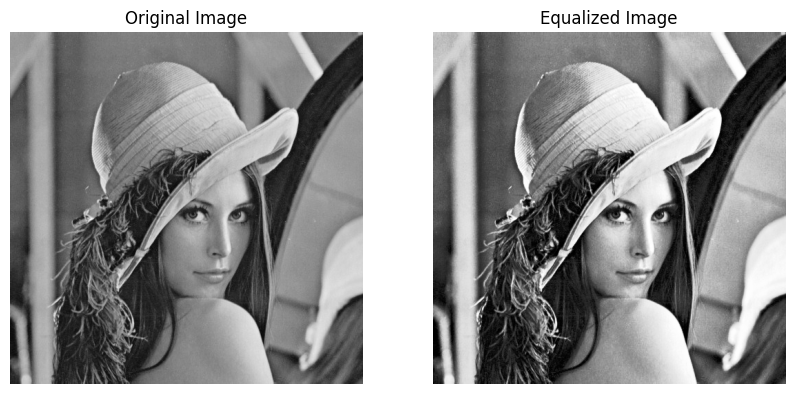

/tmp/ipykernel_525/2000093819.py:34: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(img.ravel(), 256, [0, 256])
/tmp/ipykernel_525/2000093819.py:38: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(equalized.ravel(), 256, [0, 256])


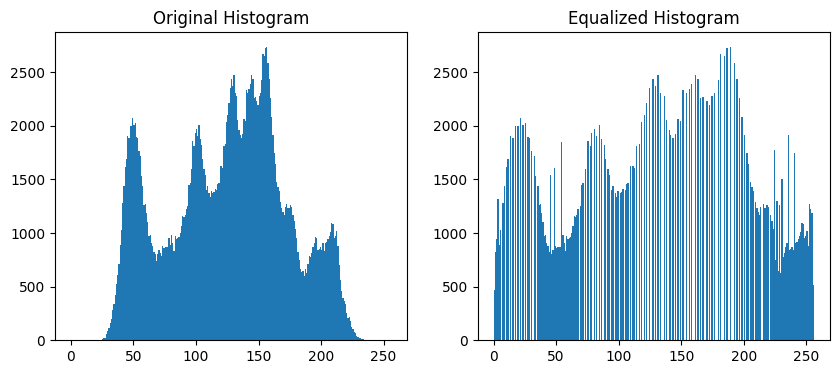

In [1]:

import cv2
import matplotlib.pyplot as plt
import urllib.request

# Download sample image
url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
urllib.request.urlretrieve(url, "input.jpg")

# Read image in grayscale
img = cv2.imread("input.jpg", 0)

# Apply histogram equalization
equalized = cv2.equalizeHist(img)

# Display images
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized, cmap="gray")
plt.title("Equalized Image")
plt.axis("off")

plt.show()

# Display histograms
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(img.ravel(), 256, [0, 256])
plt.title("Original Histogram")

plt.subplot(1, 2, 2)
plt.hist(equalized.ravel(), 256, [0, 256])
plt.title("Equalized Histogram")

plt.show()


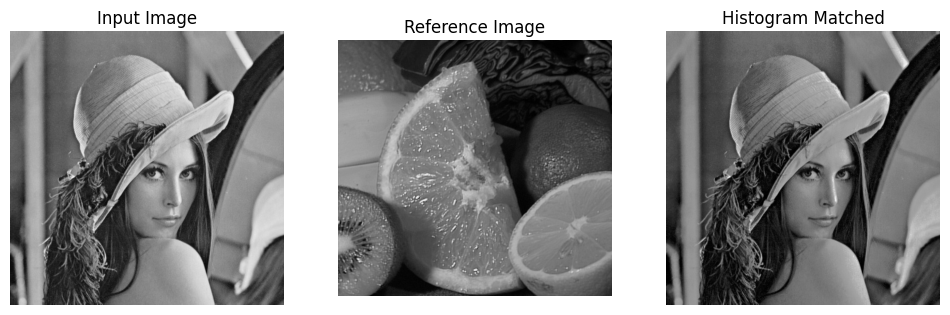

/tmp/ipykernel_525/1173247925.py:60: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(ref.ravel(), 256, [0, 256], alpha=0.5,
/tmp/ipykernel_525/1173247925.py:62: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(matched.ravel(), 256, [0, 256], alpha=0.5,


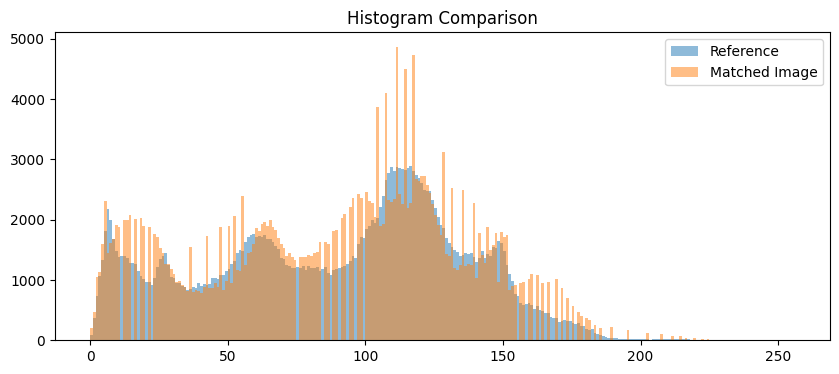

In [2]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

# Download input and reference images
url1 = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
url2 = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/fruits.jpg"

urllib.request.urlretrieve(url1, "input.jpg")
urllib.request.urlretrieve(url2, "reference.jpg")

# Read both images in grayscale
img = cv2.imread("input.jpg", 0)
ref = cv2.imread("reference.jpg", 0)

# Calculate histograms
hist_img, _ = np.histogram(img.ravel(), 256, [0, 256])
hist_ref, _ = np.histogram(ref.ravel(), 256, [0, 256])

# Calculate cumulative distribution functions (CDFs)
cdf_img = np.cumsum(hist_img).astype(np.float64)
cdf_ref = np.cumsum(hist_ref).astype(np.float64)

cdf_img /= cdf_img[-1]
cdf_ref /= cdf_ref[-1]

# Create intensity mapping
mapping = np.zeros(256, dtype=np.uint8)

for i in range(256):
    mapping[i] = np.argmin(np.abs(cdf_ref - cdf_img[i]))

# Apply histogram matching
matched = mapping[img]

# Display images
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray")
plt.title("Input Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(ref, cmap="gray")
plt.title("Reference Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(matched, cmap="gray")
plt.title("Histogram Matched")
plt.axis("off")

plt.show()

# Compare histograms
plt.figure(figsize=(10, 4))

plt.hist(ref.ravel(), 256, [0, 256], alpha=0.5,
         label="Reference")
plt.hist(matched.ravel(), 256, [0, 256], alpha=0.5,
         label="Matched Image")

plt.title("Histogram Comparison")
plt.legend()
plt.show()
